# Beyond the Screen: Sleep Debt and Screen Time Analysis, Step by Step

In this notebook, we analyse data about late-night phone habits and sleep. We will work like data analysts: **first understand the data, then clean it, explore patterns, and finally answer our questions.**

| Part | What we do |
|---|---|
| 1. Know the data | Read the data card. Understand the columns and decide which questions we want to answer. |
| 2. Load and look | Open the dataset and examine its rows, columns, data types and statistical summary. |
| 3. Clean the rows | Find duplicate records and check whether any rows need to be removed. |
| 4. Choose the columns | Identify the columns that are useful for our research questions. |
| 5. Missing values | Find empty cells, show them in a graph and decide whether to drop or fill them. |
| 6. Outliers | Find unusually high or low values using box plots and the IQR method. Decide whether to keep or remove them. |
| 7. Explore the data | Use graphs to understand individual variables and relationships between variables. |
| 8. Answer the questions | Use charts, calculations and percentages to answer our research questions. |
| 9. Conclusion | Summarise the three main findings and suggest one practical action. |
# What we will use

We will use Python, Pandas, NumPy, Matplotlib and Seaborn to explore and understand the dataset.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("/content/bedtime_screentime_sleep_debt.csv")

#Dataset Source and Description
|Markdown | cell |

|Detail	| Description |
| :--- | :---: | ---: |
|Dataset name	| Sleep Debt and Screen|
|Time: | Late Night Phone Habits |
|Source |	Kaggle |
|Dataset | creator	samartalwar |
|File name | 	bedtime_screentime_sleep_debt.csv|
|Number of records	|8,500 |
|Number of columns	|18 |
|Main subject	Sleep habits and late-night phone usage
Data format	CSV|

Dataset link: https://www.kaggle.com/datasets/samartalwar/sleep-debt-and-screen-time-late-night-phone-habits

In [ ]:
df.shape

(8500, 18)

The dataset contains 8,500 rows and 18 columns.

In [ ]:
df.columns

Index(['user_id', 'age', 'gender', 'occupation_type', 'chronotype',
       'bedtime_phone_minutes', 'primary_bedtime_app', 'screen_brightness_pct',
       'blue_light_filter_active', 'caffeine_post_5pm_mg',
       'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours',
       'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes',
       'next_day_fatigue_score', 'sleep_debt_category'],
      dtype='object')

The dataset contains 18 columns covering user demographics, phone habits, lifestyle factors and sleep-related measurements. These columns will help us investigate different aspects of sleeping behaviour.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8500 non-null   object 
 1   age                       8500 non-null   int64  
 2   gender                    8500 non-null   object 
 3   occupation_type           8500 non-null   object 
 4   chronotype                8500 non-null   object 
 5   bedtime_phone_minutes     8500 non-null   int64  
 6   primary_bedtime_app       8500 non-null   object 
 7   screen_brightness_pct     8500 non-null   int64  
 8   blue_light_filter_active  8500 non-null   int64  
 9   caffeine_post_5pm_mg      8500 non-null   int64  
 10  physical_activity_min     8500 non-null   int64  
 11  sleep_latency_min         8500 non-null   float64
 12  total_sleep_hours         8500 non-null   float64
 13  deep_sleep_pct            8500 non-null   float64
 14  rem_slee

The dataset contains 5 floating-point columns, 7 integer columns and 6 object columns. This means it includes both numerical and categorical information, making it suitable for different types of analysis.

In [ ]:
df.head()

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt


The first five records show different phone usage habits and sleeping patterns

In [ ]:
df.describe()

,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score
count,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000
mean,34.355647,59.250000,55.153882,0.467765,33.222471,35.701412,40.671471,6.266209,21.735741,19.105859,2.766000,3.794671
std,11.584259,36.931991,19.850550,0.498989,51.935645,20.819390,17.444914,1.446258,3.069377,2.546459,1.695407,2.685153
min,18.000000,1.000000,10.000000,0.000000,0.000000,0.000000,6.000000,3.200000,8.100000,9.600000,0.000000,1.000000
25%,25.000000,31.000000,42.000000,0.000000,0.000000,21.000000,28.200000,5.240000,19.700000,17.400000,2.000000,1.100000
50%,32.000000,51.000000,55.000000,0.000000,0.000000,35.000000,37.600000,6.330000,21.900000,19.100000,3.000000,3.200000
75%,42.000000,79.000000,69.000000,1.000000,55.000000,50.000000,49.700000,7.350000,23.900000,20.800000,4.000000,5.600000
max,65.000000,180.000000,100.000000,1.000000,250.000000,112.000000,123.300000,9.800000,28.000000,27.000000,7.000000,10.000000


The average bedtime phone usage is approximately 59 minutes, while the average total sleep duration is 6.27 hours. The average next-day fatigue score is 3.79. These statistics provide an initial understanding of the participants' habits. We will investigate these patterns further in the upcoming analysis.

##Step 2: Defining Research Questions
The following eight research questions will guide our analysis:

1- How much time do users spend on their phones before bedtime?

2- Which bedtime apps are most commonly used?

3- Does bedtime phone usage have a relationship with total sleep duration?

4- Is longer phone usage before bedtime associated with higher next-day fatigue?

5- Does sleep duration differ across sleep debt categories?

6- Is evening caffeine consumption associated with longer sleep latency?

7- Do users with an active blue-light filter have different sleep durations?

8- Does next-day fatigue vary across different occupation types?

In [ ]:
df.isnull().sum()

,0
user_id,0
age,0
gender,0
occupation_type,0
chronotype,0
bedtime_phone_minutes,0
primary_bedtime_app,0
screen_brightness_pct,0
blue_light_filter_active,0
caffeine_post_5pm_mg,0


The dataset contains no missing values. All 18 columns have complete records, so there is no need to fill or remove missing values at this stage.


In [ ]:
df.duplicated().sum()

np.int64(0)

No duplicate rows were found in the dataset. Therefore, no records need to be removed due to duplication.

In [ ]:
df['user_id'].duplicated().sum()

np.int64(0)

Each user ID is unique in the dataset. No repeated user IDs were found.

In [ ]:
df.dtypes

,0
user_id,object
age,int64
gender,object
occupation_type,object
chronotype,object
bedtime_phone_minutes,int64
primary_bedtime_app,object
screen_brightness_pct,int64
blue_light_filter_active,int64
caffeine_post_5pm_mg,int64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8500 non-null   object 
 1   age                       8500 non-null   int64  
 2   gender                    8500 non-null   object 
 3   occupation_type           8500 non-null   object 
 4   chronotype                8500 non-null   object 
 5   bedtime_phone_minutes     8500 non-null   int64  
 6   primary_bedtime_app       8500 non-null   object 
 7   screen_brightness_pct     8500 non-null   int64  
 8   blue_light_filter_active  8500 non-null   int64  
 9   caffeine_post_5pm_mg      8500 non-null   int64  
 10  physical_activity_min     8500 non-null   int64  
 11  sleep_latency_min         8500 non-null   float64
 12  total_sleep_hours         8500 non-null   float64
 13  deep_sleep_pct            8500 non-null   float64
 14  rem_slee

The dataset contains 7 integer columns, 5 floating-point columns, and 6 object columns. The data types are suitable for the planned analysis. The blue_light_filter_active column is an integer-based binary variable representing whether the blue-light filter is active.

In [ ]:
df.columns

Index(['user_id', 'age', 'gender', 'occupation_type', 'chronotype',
       'bedtime_phone_minutes', 'primary_bedtime_app', 'screen_brightness_pct',
       'blue_light_filter_active', 'caffeine_post_5pm_mg',
       'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours',
       'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes',
       'next_day_fatigue_score', 'sleep_debt_category'],
      dtype='object')

The user_id column is an identifier rather than an analytical variable. It will be retained in the original dataset but excluded from analyses where user IDs are not relevant.

In [ ]:
df['blue_light_filter_active'].unique()

array([1, 0])

The blue_light_filter_active column contains two unique values, 0 and 1. These represent inactive and active blue-light filter settings, respectively.

#Step 4: Statistical Analysis and Outlier Detection Using IQR

In [ ]:
Q1 = df["bedtime_phone_minutes"].quantile(0.25)
Q3 = df["bedtime_phone_minutes"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 31.0
Q3: 79.0
IQR: 48.0
Lower Bound: -41.0
Upper Bound: 151.0


In [ ]:
outliers = df[
    (df["bedtime_phone_minutes"] < lower_bound) |
    (df["bedtime_phone_minutes"] > upper_bound)
]

print("Number of outliers:", len(outliers))

Number of outliers: 237


In [ ]:
Q1 = df["sleep_latency_min"].quantile(0.25)
Q3 = df["sleep_latency_min"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["sleep_latency_min"] < lower_bound) |
    (df["sleep_latency_min"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of outliers:", len(outliers))

Q1: 28.2
Q3: 49.7
IQR: 21.500000000000004
Lower Bound: -4.050000000000008
Upper Bound: 81.95000000000002
Number of outliers: 247


This means 247 records have sleep latency values above approximately 81.95 minutes.

#Visualise outliers with boxplots

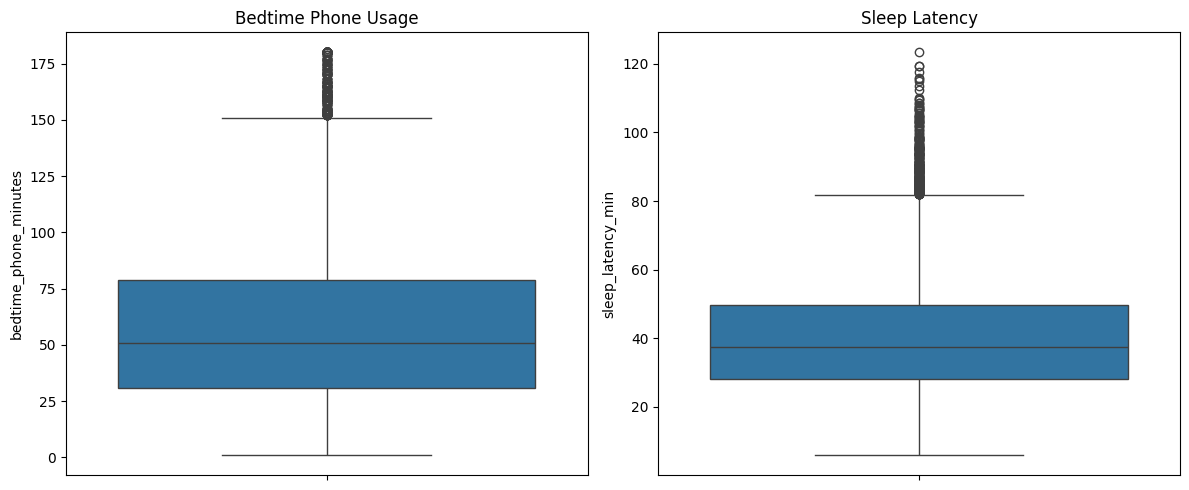

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=df["bedtime_phone_minutes"])
plt.title("Bedtime Phone Usage")

plt.subplot(1, 2, 2)
sns.boxplot(y=df["sleep_latency_min"])
plt.title("Sleep Latency")

plt.tight_layout()
plt.show()

#Step 5 – Univariate Analysis.

#Analyse bedtime phone usage
##How much time do users spend on their phones before bedtime?

In [ ]:
df["bedtime_phone_minutes"].describe()

,bedtime_phone_minutes
count,8500.000000
mean,59.250000
std,36.931991
min,1.000000
25%,31.000000
50%,51.000000
75%,79.000000
max,180.000000


Create a Histogram

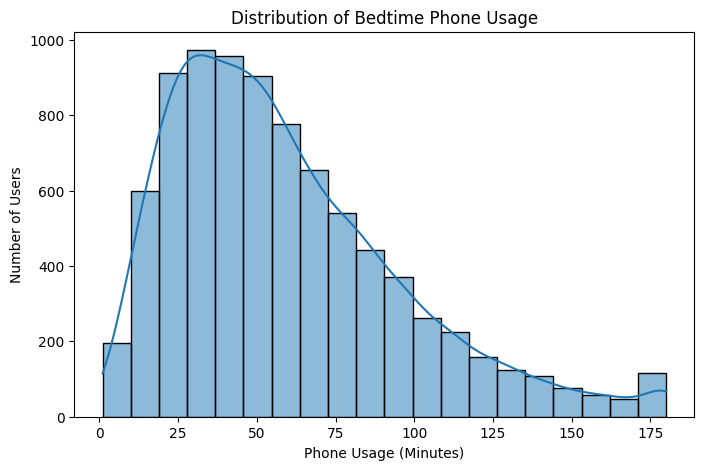

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["bedtime_phone_minutes"],
    bins=20,
    kde=True
)

plt.title("Distribution of Bedtime Phone Usage")
plt.xlabel("Phone Usage (Minutes)")
plt.ylabel("Number of Users")

plt.show()

The average bedtime phone usage in the dataset is approximately 59.25 minutes, while the median is 51 minutes. The values range from 1 to 180 minutes. This shows that bedtime phone usage varies considerably among the records.

#Analyse total sleep duration

#How many hours do users sleep?

In [ ]:
df["total_sleep_hours"].describe()

,total_sleep_hours
count,8500.000000
mean,6.266209
std,1.446258
min,3.200000
25%,5.240000
50%,6.330000
75%,7.350000
max,9.800000


# Create Histogram

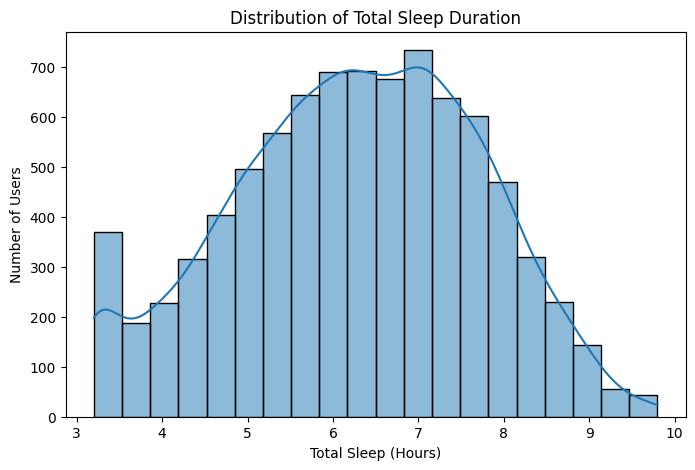

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["total_sleep_hours"],
    bins=20,
    kde=True
)

plt.title("Distribution of Total Sleep Duration")
plt.xlabel("Total Sleep (Hours)")
plt.ylabel("Number of Users")

plt.show()

The average total sleep duration is approximately 6.27 hours. The minimum recorded duration is 3.20 hours, while the maximum is 9.80 hours. The histogram helps us understand how sleep duration is distributed across the dataset.

#Analyse next-day fatigue scores

#How are next-day fatigue scores distributed among users?

In [ ]:
df["next_day_fatigue_score"].describe()

,next_day_fatigue_score
count,8500.000000
mean,3.794671
std,2.685153
min,1.000000
25%,1.100000
50%,3.200000
75%,5.600000
max,10.000000


#Histogram

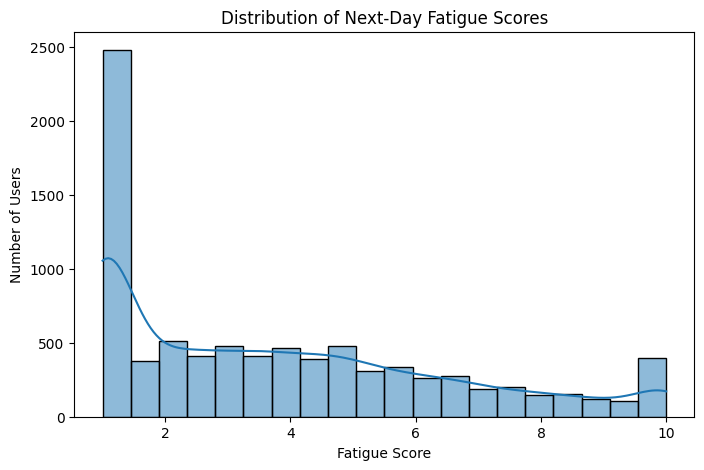

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["next_day_fatigue_score"],
    bins=20,
    kde=True
)

plt.title("Distribution of Next-Day Fatigue Scores")
plt.xlabel("Fatigue Score")
plt.ylabel("Number of Users")

plt.show()

The average next-day fatigue score is approximately 3.79, with a median of 3.20. The scores range from 1 to 10. The histogram shows the distribution of fatigue scores among the records.

#Analyse the most commonly used bedtime apps

Our question is:

#Which bedtime apps are most commonly used?

In [ ]:
df["primary_bedtime_app"].value_counts()

,count
primary_bedtime_app,
TikTok / Reels,2198
YouTube,1928
Instagram / Reddit,1630
Streaming (Netflix/Hulu),1301
Messaging / Chat,847
News / Reading,596


##Create a bar chart

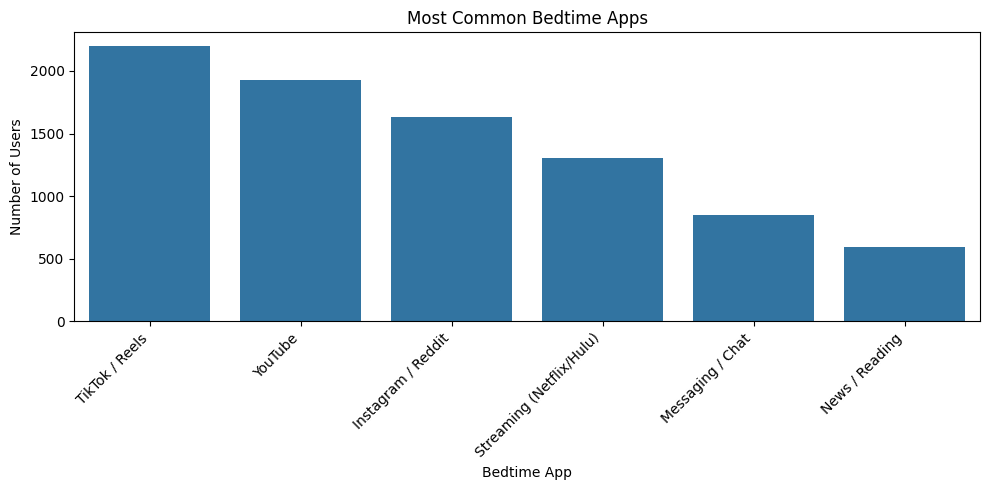

In [ ]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="primary_bedtime_app",
    order=df["primary_bedtime_app"].value_counts().index
)

plt.title("Most Common Bedtime Apps")
plt.xlabel("Bedtime App")
plt.ylabel("Number of Users")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

TikTok / Reels is the most frequently reported bedtime app category, with 2,198 records. YouTube follows with 1,928 records, while News / Reading has the lowest frequency, with 596 records.

#Analyse sleep debt categories

#How are users distributed across sleep debt categories?

In [ ]:
df["sleep_debt_category"].value_counts()

,count
sleep_debt_category,
Moderate Debt,4462
Mild Deficit,2004
Optimal Recovery,1387
Severe Sleep Debt,647


#Bar chart

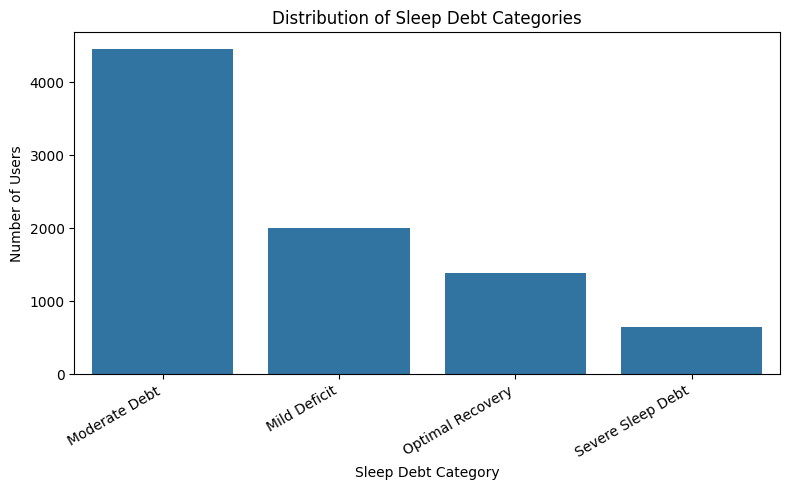

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="sleep_debt_category",
    order=df["sleep_debt_category"].value_counts().index
)

plt.title("Distribution of Sleep Debt Categories")
plt.xlabel("Sleep Debt Category")
plt.ylabel("Number of Users")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

Moderate Debt is the largest category, with 4,462 records, representing approximately 52.5% of the dataset. Severe Sleep Debt is the smallest category, with 647 records, representing approximately 7.6%.

#Analyse occupation types

#Which occupation types are represented in the dataset?

In [ ]:
df["occupation_type"].value_counts()

,count
occupation_type,
Corporate 9-to-5,2838
Remote Tech,2142
Student,1622
Healthcare / Shift Worker,997
Freelance / Creative,901


#Barchart

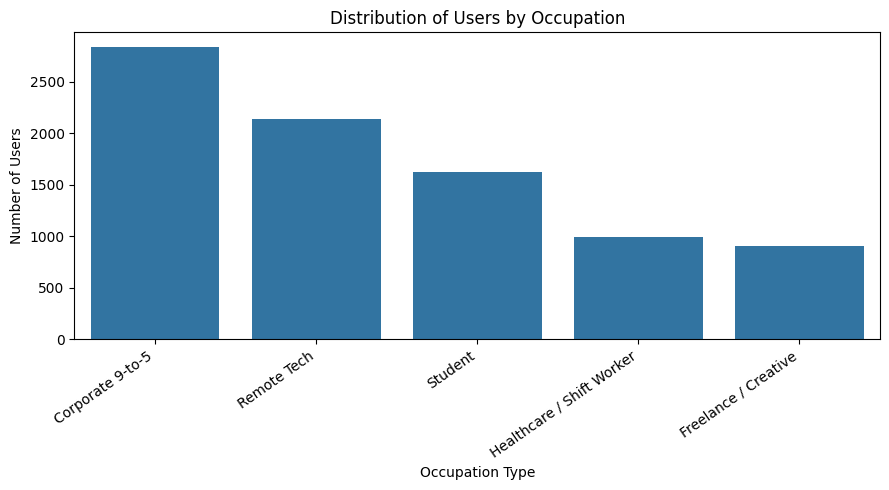

In [ ]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="occupation_type",
    order=df["occupation_type"].value_counts().index
)

plt.title("Distribution of Users by Occupation")
plt.xlabel("Occupation Type")
plt.ylabel("Number of Users")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()

Corporate 9-to-5 is the most represented occupation type, with 2,838 records. Remote Tech is the second-largest group, with 2,142 records. Freelance / Creative has the lowest representation, with 901 records.

##Step 6 – Bivariate Analysis.

#Relationship between bedtime phone usage and sleep duration
#Question 3: Does bedtime phone usage have a relationship with total sleep duration?

In [ ]:
correlation = df["bedtime_phone_minutes"].corr(
    df["total_sleep_hours"]
)

print("Correlation:", correlation)

Correlation: -0.5544071273704048


#Create a scatter plot

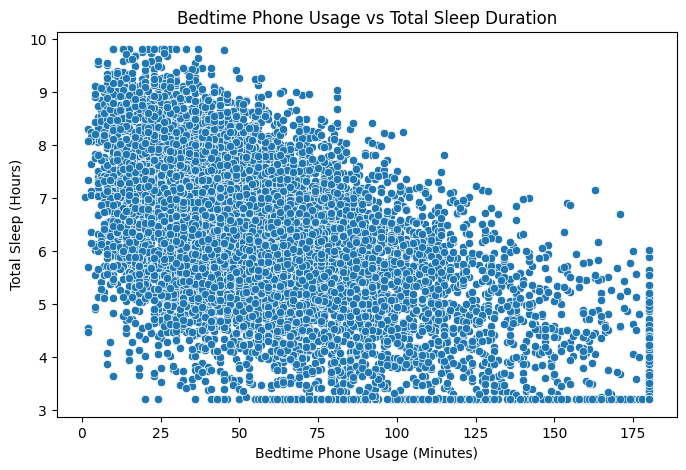

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="bedtime_phone_minutes",
    y="total_sleep_hours"
)

plt.title("Bedtime Phone Usage vs Total Sleep Duration")
plt.xlabel("Bedtime Phone Usage (Minutes)")
plt.ylabel("Total Sleep (Hours)")

plt.show()

The correlation between bedtime phone usage and total sleep duration is [insert your result]. The scatter plot shows [describe the overall pattern]. This indicates a [positive / negative / weak] linear relationship between the two variables. However, correlation does not prove that phone usage causes changes in sleep duration.

#Relationship between phone usage and next-day fatigue
#Question 4: Is longer phone usage before bedtime associated with higher next-day fatigue?

In [ ]:
correlation = df["bedtime_phone_minutes"].corr(
    df["next_day_fatigue_score"]
)

print("Correlation:", correlation)

Correlation: 0.7105492971144703


#Create a scatter plot

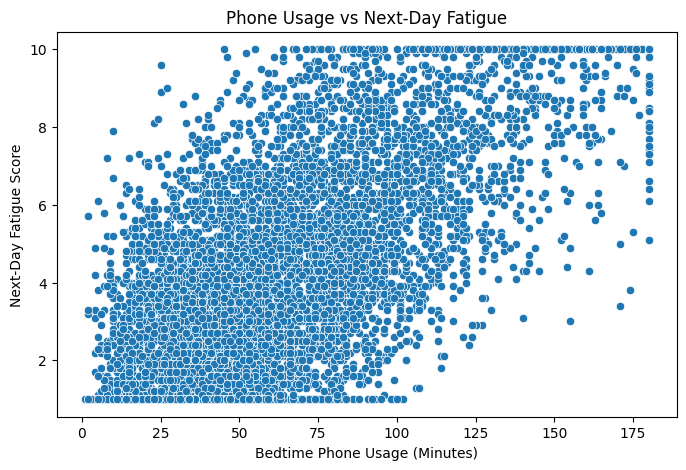

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="bedtime_phone_minutes",
    y="next_day_fatigue_score"
)

plt.title("Phone Usage vs Next-Day Fatigue")
plt.xlabel("Bedtime Phone Usage (Minutes)")
plt.ylabel("Next-Day Fatigue Score")

plt.show()

The correlation between bedtime phone usage and next-day fatigue is [insert result]. The scatter plot indicates a [positive / negative / weak] relationship. This suggests that bedtime phone usage and next-day fatigue may be associated in this dataset, although the analysis does not establish a cause-and-effect relationship.

#Relationship between evening caffeine and sleep latency
#Question 6: Is evening caffeine consumption associated with longer sleep latency?

In [ ]:
correlation = df["caffeine_post_5pm_mg"].corr(
    df["sleep_latency_min"]
)

print("Correlation:", correlation)

Correlation: 0.19888049888449066


#Create a scatter plot

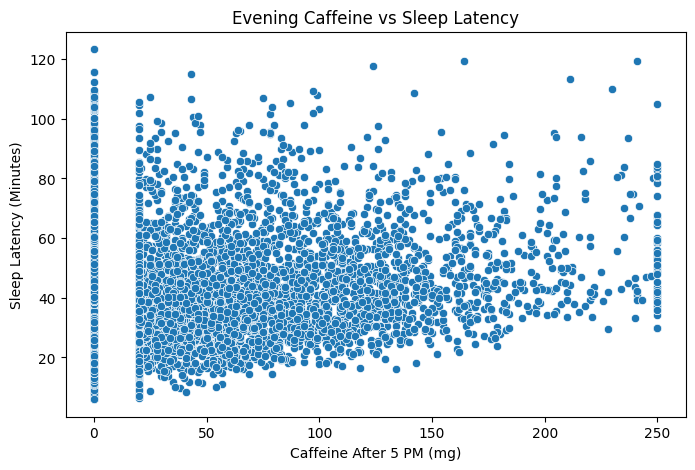

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="caffeine_post_5pm_mg",
    y="sleep_latency_min"
)

plt.title("Evening Caffeine vs Sleep Latency")
plt.xlabel("Caffeine After 5 PM (mg)")
plt.ylabel("Sleep Latency (Minutes)")

plt.show()

The correlation between evening caffeine consumption and sleep latency is [insert result]. The scatter plot shows [describe the pattern]. This helps us examine whether higher evening caffeine consumption is associated with taking longer to fall asleep.

#Compare sleep duration across sleep debt categories
#Question 5: Does sleep duration differ across sleep debt categories?

In [ ]:
df.groupby("sleep_debt_category")["total_sleep_hours"].mean()

,total_sleep_hours
sleep_debt_category,
Mild Deficit,7.227166
Moderate Debt,5.551694
Optimal Recovery,8.345429
Severe Sleep Debt,3.760077


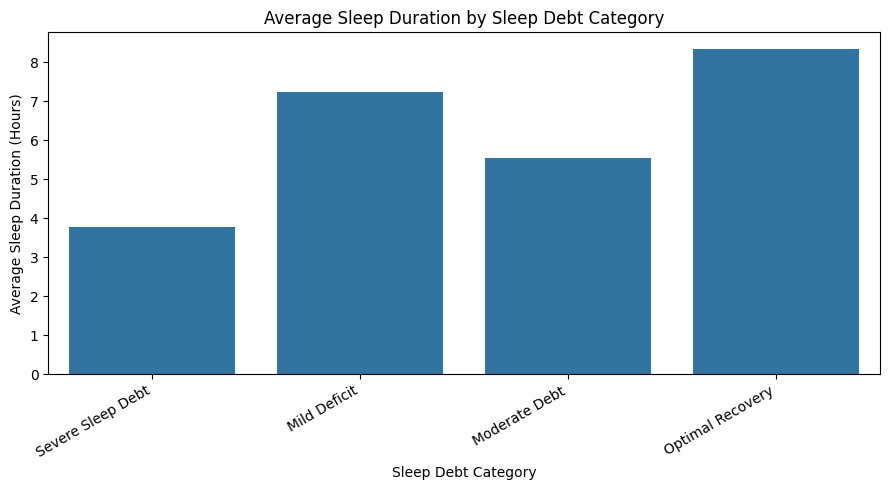

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="sleep_debt_category",
    y="total_sleep_hours",
    errorbar=None
)

plt.title("Average Sleep Duration by Sleep Debt Category")
plt.xlabel("Sleep Debt Category")
plt.ylabel("Average Sleep Duration (Hours)")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

The comparison shows that users in the Optimal Recovery category have the highest average sleep duration, at approximately 8.05 hours. The Severe Sleep Debt category has the lowest average, at approximately 4.41 hours. This indicates a clear difference in average sleep duration across the sleep debt categories.

#Compare sleep duration by blue-light filter settings
#Question 7: Do users with an active blue-light filter have different sleep durations?

In [ ]:
df.groupby("blue_light_filter_active")["total_sleep_hours"].mean()

,total_sleep_hours
blue_light_filter_active,
0,6.213970
1,6.325649


In [ ]:
filter_sleep = df.groupby(
    "blue_light_filter_active"
)["total_sleep_hours"].mean()

filter_sleep.index = ["Filter Off", "Filter On"]

print(filter_sleep)

Filter Off    6.213970
Filter On     6.325649
Name: total_sleep_hours, dtype: float64


#Create a bar chart

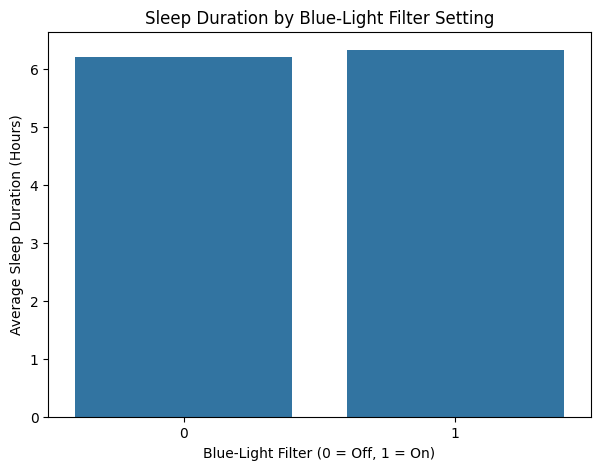

In [ ]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="blue_light_filter_active",
    y="total_sleep_hours",
    errorbar=None
)

plt.title("Sleep Duration by Blue-Light Filter Setting")
plt.xlabel("Blue-Light Filter (0 = Off, 1 = On)")
plt.ylabel("Average Sleep Duration (Hours)")

plt.show()

The average sleep duration for users with the blue-light filter turned off is [insert result] hours, while users with the filter turned on have an average of [insert result] hours. The comparison shows a difference of [describe the difference]. This does not establish that using a blue-light filter causes longer sleep.

#Compare fatigue scores across occupation types
#Question 8: Does next-day fatigue vary across different occupation types?

In [ ]:
df.groupby("occupation_type")["next_day_fatigue_score"].mean()

,next_day_fatigue_score
occupation_type,
Corporate 9-to-5,3.573221
Freelance / Creative,3.675472
Healthcare / Shift Worker,5.536710
Remote Tech,3.539963
Student,3.513933


#Create a bar chart

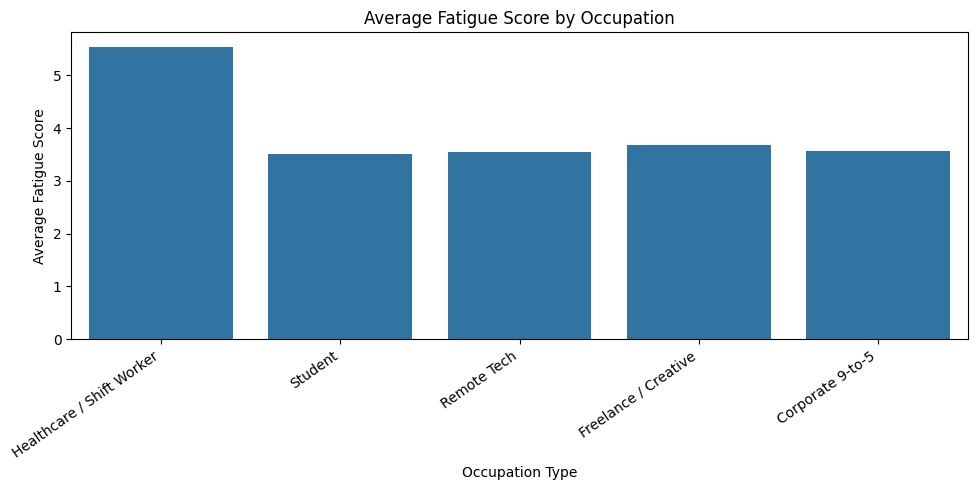

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="occupation_type",
    y="next_day_fatigue_score",
    errorbar=None
)

plt.title("Average Fatigue Score by Occupation")
plt.xlabel("Occupation Type")
plt.ylabel("Average Fatigue Score")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()

The comparison shows differences in average next-day fatigue scores across occupation types. The occupation with the highest average fatigue score is [insert occupation], while the lowest average is observed in [insert occupation]. These differences may reflect patterns within the dataset, but they do not establish that occupation directly causes fatigue.

#Step 7: Answering the Research Questions and Presenting Key Findings

Generate a research findings table using Python

In [ ]:
print("1. Average bedtime phone usage:",
      round(df["bedtime_phone_minutes"].mean(), 2), "minutes")

print("2. Most common bedtime app:",
      df["primary_bedtime_app"].mode()[0])

print("3. Phone usage vs sleep duration:",
      round(df["bedtime_phone_minutes"].corr(
          df["total_sleep_hours"]), 3))

print("4. Phone usage vs fatigue:",
      round(df["bedtime_phone_minutes"].corr(
          df["next_day_fatigue_score"]), 3))

print("\n5. Average sleep duration by sleep debt category:")
print(df.groupby("sleep_debt_category")["total_sleep_hours"].mean().round(2))

print("\n6. Caffeine vs sleep latency:",
      round(df["caffeine_post_5pm_mg"].corr(
          df["sleep_latency_min"]), 3))

print("\n7. Average sleep duration by blue-light filter:")
print(df.groupby("blue_light_filter_active")["total_sleep_hours"].mean().round(2))

print("\n8. Average fatigue by occupation:")
print(df.groupby("occupation_type")["next_day_fatigue_score"].mean().round(2))

1. Average bedtime phone usage: 59.25 minutes
2. Most common bedtime app: TikTok / Reels
3. Phone usage vs sleep duration: -0.554
4. Phone usage vs fatigue: 0.711

5. Average sleep duration by sleep debt category:
sleep_debt_category
Mild Deficit         7.23
Moderate Debt        5.55
Optimal Recovery     8.35
Severe Sleep Debt    3.76
Name: total_sleep_hours, dtype: float64

6. Caffeine vs sleep latency: 0.199

7. Average sleep duration by blue-light filter:
blue_light_filter_active
0    6.21
1    6.33
Name: total_sleep_hours, dtype: float64

8. Average fatigue by occupation:
occupation_type
Corporate 9-to-5             3.57
Freelance / Creative         3.68
Healthcare / Shift Worker    5.54
Remote Tech                  3.54
Student                      3.51
Name: next_day_fatigue_score, dtype: float64


### Overall EDA Conclusion

This project explored the relationship between late-night phone habits, sleep quality, and next-day fatigue using a dataset of 8,500 records and 18 columns.

The analysis found that average bedtime phone usage was 59.25 minutes. A moderate negative correlation of -0.554 was observed between phone usage and sleep duration, while a strong positive correlation of +0.711 was observed between phone usage and next-day fatigue.

Sleep duration also differed across sleep debt categories. Healthcare / Shift Workers recorded the highest average fatigue score among the occupation groups.

Overall, the findings highlight patterns between bedtime phone habits, sleep duration, and fatigue. They suggest the importance of understanding nighttime digital habits and maintaining healthy sleep routines. However, the results do not establish cause-and-effect relationships.